## 可視化例

In [7]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from env import Env
from toio_RL.common.q_plotter import QPlotter

### 学習曲線の可視化

In [8]:
csv_path = Path("test_eval.csv")
df = pd.read_csv(csv_path, index_col=0)
df.head()

,step,eval_rewards
0,10,0.0
1,20,0.0
2,30,0.0
3,40,0.0
4,50,0.0


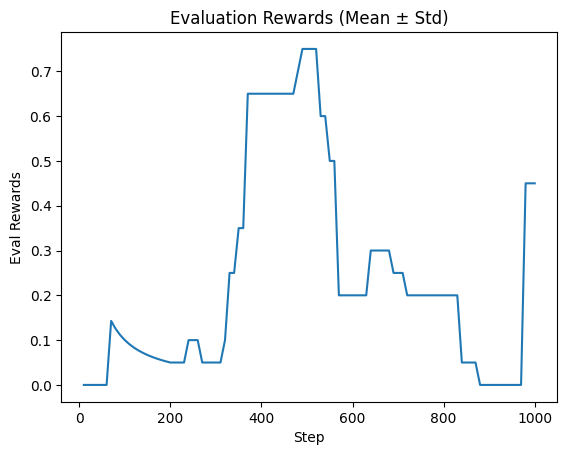

In [9]:
window_size = 20
df["rewards_smooth"] = (
    df["eval_rewards"].rolling(window=window_size, min_periods=1).mean()
)
sns.lineplot(data=df, x="step", y="rewards_smooth", errorbar="sd")

plt.xlabel("Step")
plt.ylabel("Eval Rewards")
plt.title("Evaluation Rewards (Mean ± Std)")
plt.show()


### Q関数の可視化

C:\Users\Keiichi Namikoshi\Desktop\2025_0425_toio\toio_RL\common\q_plotter.py:73: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  self.fig.show()


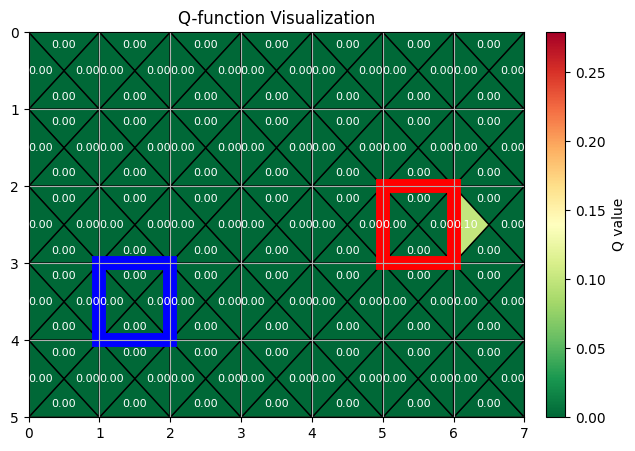

In [10]:
Q = np.load("test_q_trained.npy")

env = Env(mode="sim")
env._agent_pos  = (1, 3)
env._target_pos = (5, 2)

QPlotter(env).plot_q(Q)